# Multimodal Alzheimer's Disease Classification — Dataset & Split Statistics

Questo notebook analizza in dettaglio le statistiche e la distribuzione delle classi per tutti i **4 TASK** di classificazione:
1. **`cn_ad`**: Cognitively Normal (CN) vs Alzheimer's Disease (AD) — *Binario*
2. **`cn_mci`**: Cognitively Normal (CN) vs Mild Cognitive Impairment (MCI) — *Binario*
3. **`mci_ad`**: Mild Cognitive Impairment (MCI) vs Alzheimer's Disease (AD) — *Binario*
4. **`cn_mci_ad`**: CN vs MCI vs AD — *Multiclasse a 3 vie*

---

### Sorgenti Dati:
- **Dataset Originale (senza split)**: `data/processed/population_topology/<task>/population_dataset.csv`
- **Stratified 5-Fold Cross Validation + Holdout Test**: `data/processed/splits/<task>/`
  - Split Test indipendente: `test.csv` (10% del dataset)
  - Split 5-Fold CV: `folds/<fold_id>/train.csv` (80% del train-val) e `val.csv` (20% del train-val)


In [1]:
import os
import sys
from pathlib import Path
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import seaborn as sns
from IPython.display import display

# Assicuriamoci che la working directory sia la root del repository
if Path.cwd().name == 'notebooks':
    os.chdir(Path.cwd().parent)
print(f"Working Directory del Progetto: {Path.cwd()}")

# Configurazione stile Seaborn / Matplotlib per grafici scientifici ad alta risoluzione
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['figure.dpi'] = 120
plt.rcParams['axes.titlesize'] = 14
plt.rcParams['axes.titleweight'] = 'bold'
plt.rcParams['axes.labelsize'] = 12
plt.rcParams['axes.labelweight'] = 'bold'
plt.rcParams['xtick.labelsize'] = 10
plt.rcParams['ytick.labelsize'] = 10
plt.rcParams['legend.fontsize'] = 11

# Palette colori fissa e coerente per classe diagnostica
CLASS_COLORS = {
    'CN': '#2b5c8f',    # Blu solido
    'MCI': '#e08214',   # Ambra / Arancio
    'AD': '#c0392b',    # Rosso cremisi
}

TASKS = ['cn_ad', 'cn_mci', 'mci_ad', 'cn_mci_ad']
TASK_LABELS = {
    'cn_ad': 'CN vs AD (Binary)',
    'cn_mci': 'CN vs MCI (Binary)',
    'mci_ad': 'MCI vs AD (Binary)',
    'cn_mci_ad': 'CN vs MCI vs AD (3-Class Multiclass)',
}

print("Setup completato con successo. Palette colori e configurazioni grafiche pronte.")


Working Directory del Progetto: /home/raffaele/art/multimodal-alzheimer-classification
Setup completato con successo. Palette colori e configurazioni grafiche pronte.


In [2]:
def load_task_datasets(task_name: str) -> dict:
    """
    Carica tutti i dataset per un determinato task:
    - Dataset originale non suddiviso da population_topology
    - Split test holdout da splits/<task>/test.csv
    - Folds 0-4 (train e val) da splits/<task>/folds/<k>/
    """
    base_pop_dir = Path("data/processed/population_topology") / task_name
    base_split_dir = Path("data/processed/splits") / task_name
    
    datasets = {}
    
    # 1. Dataset Originale
    pop_csv = base_pop_dir / "population_dataset.csv"
    if not pop_csv.exists():
        raise FileNotFoundError(f"File non trovato: {pop_csv.resolve()}")
    datasets['Original'] = pd.read_csv(pop_csv)
    
    # 2. Test Set Holdout
    test_csv = base_split_dir / "test.csv"
    if test_csv.exists():
        datasets['Test'] = pd.read_csv(test_csv)
        
    # 3. 5-Fold Cross Validation Splits
    for fold in range(5):
        train_csv = base_split_dir / "folds" / str(fold) / "train.csv"
        val_csv = base_split_dir / "folds" / str(fold) / "val.csv"
        if train_csv.exists() and val_csv.exists():
            datasets[f'F{fold}_Train'] = pd.read_csv(train_csv)
            datasets[f'F{fold}_Val'] = pd.read_csv(val_csv)
            
    return datasets


def extract_split_statistics(datasets: dict) -> pd.DataFrame:
    """
    Costruisce una tabella strutturata con conteggi, percentuali e statistiche demografiche
    per ciascuno split.
    """
    rows = []
    
    for split_name, df in datasets.items():
        total = len(df)
        patients = df['PTID'].nunique() if 'PTID' in df else total
        counts = df['original_class'].value_counts().to_dict()
        
        row = {
            'Split': split_name,
            'Total Scans': total,
            'Unique Patients': patients,
            'CN Count': counts.get('CN', 0),
            'MCI Count': counts.get('MCI', 0),
            'AD Count': counts.get('AD', 0),
            'CN %': (counts.get('CN', 0) / total * 100) if total > 0 else 0.0,
            'MCI %': (counts.get('MCI', 0) / total * 100) if total > 0 else 0.0,
            'AD %': (counts.get('AD', 0) / total * 100) if total > 0 else 0.0,
            'Age Mean±Std': f"{df['AGE'].mean():.1f} ± {df['AGE'].std():.1f}" if 'AGE' in df else 'N/A',
            'MMSE Mean±Std': f"{df['MMSE'].mean():.1f} ± {df['MMSE'].std():.1f}" if 'MMSE' in df else 'N/A',
            'Has PET %': f"{(df['has_pet'].sum() / total * 100):.1f}%" if 'has_pet' in df else 'N/A',
            'Paired Both %': f"{(df['has_both'].sum() / total * 100):.1f}%" if 'has_both' in df else 'N/A'
        }
        rows.append(row)
        
    return pd.DataFrame(rows)

print("Funzioni di caricamento ed estrazione statistiche definite.")


Funzioni di caricamento ed estrazione statistiche definite.


In [3]:
def plot_task_analysis(task_name: str, datasets: dict, stats_df: pd.DataFrame):
    """
    Genera un pannello grafico scientifico completo e di alta qualità per un task:
    - Pannello 1: Conteggio assoluto per classe su Dataset Originale, Test e ciascun Fold (Train & Val).
    - Pannello 2: Distribuzione percentuale normalizzata (100% Stacked Bar) per verificare la perfetta stratificazione.
    - Pannello 3: Ripartizione volumetrica Train/Val/Test e disponibilità multimodale (MRI vs PET).
    """
    present_classes = [c for c in ['CN', 'MCI', 'AD'] if stats_df[f'{c} Count'].sum() > 0]
    
    splits_order = ['Original', 'Test']
    for f in range(5):
        splits_order.extend([f'F{f}_Train', f'F{f}_Val'])
        
    plot_df = stats_df[stats_df['Split'].isin(splits_order)].copy()
    plot_df['Split'] = pd.Categorical(plot_df['Split'], categories=splits_order, ordered=True)
    plot_df = plot_df.sort_values('Split')
    
    fig = plt.figure(figsize=(18, 12))
    gs = fig.add_gridspec(2, 2, height_ratios=[1.2, 1.0], width_ratios=[1.5, 1.0], hspace=0.35, wspace=0.25)
    
    # ----------------------------------------------------
    # PANNELLO 1: Conteggi Assoluti delle Classi per Split
    # ----------------------------------------------------
    ax1 = fig.add_subplot(gs[0, :])
    
    x = np.arange(len(plot_df))
    n_classes = len(present_classes)
    bar_width = 0.8 / n_classes
    
    for i, cls in enumerate(present_classes):
        counts = plot_df[f'{cls} Count'].values
        pcts = plot_df[f'{cls} %'].values
        pos = x - 0.4 + (i + 0.5) * bar_width
        
        bars = ax1.bar(
            pos, counts, width=bar_width,
            label=f'Classe {cls}', color=CLASS_COLORS[cls],
            edgecolor='black', linewidth=0.8, alpha=0.9
        )
        
        # Etichette numeriche sopra le barre
        for bar, count, pct in zip(bars, counts, pcts):
            yval = bar.get_height()
            if yval > 0:
                ax1.annotate(
                    f'{int(count):,}\n({pct:.1f}%)',
                    xy=(bar.get_x() + bar.get_width() / 2, yval),
                    xytext=(0, 4), textcoords="offset points",
                    ha='center', va='bottom', fontsize=8.5, weight='bold',
                    color='#1a1a1a'
                )
                
    # Separatori verticali visivi tra blocchi
    ax1.axvline(x=0.5, color='gray', linestyle='--', linewidth=1.2, alpha=0.7)
    ax1.axvline(x=1.5, color='gray', linestyle='--', linewidth=1.2, alpha=0.7)
    for sep in range(3, len(plot_df), 2):
        ax1.axvline(x=sep - 0.5, color='lightgray', linestyle=':', linewidth=1.0)
        
    ax1.set_xticks(x)
    ax1.set_xticklabels(plot_df['Split'], rotation=25, ha='right', weight='bold')
    ax1.set_ylabel('Numero di Scansioni', weight='bold')
    ax1.set_title(f'Distribuzione Assoluta delle Classi — Task: {TASK_LABELS[task_name]}', pad=15)
    ax1.legend(loc='upper right', frameon=True, facecolor='white', framealpha=0.9)
    ax1.set_ylim(0, float(plot_df[[f'{c} Count' for c in present_classes]].values.max()) * 1.25)
    ax1.yaxis.set_major_formatter(ticker.StrMethodFormatter('{x:,.0f}'))
    
    # ----------------------------------------------------
    # PANNELLO 2: Percentuali Relative (Stratificazione 100%)
    # ----------------------------------------------------
    ax2 = fig.add_subplot(gs[1, 0])
    
    bottom = np.zeros(len(plot_df))
    for cls in present_classes:
        pcts = plot_df[f'{cls} %'].values
        bars = ax2.bar(
            plot_df['Split'], pcts, bottom=bottom,
            width=0.65, label=cls, color=CLASS_COLORS[cls],
            edgecolor='white', linewidth=1.0, alpha=0.92
        )
        # Etichette interne con percentuale
        for j, (bar, pct) in enumerate(zip(bars, pcts)):
            if pct > 8:
                ax2.text(
                    bar.get_x() + bar.get_width() / 2,
                    bottom[j] + pct / 2,
                    f'{pct:.1f}%',
                    ha='center', va='center', color='white',
                    weight='bold', fontsize=9
                )
        bottom += pcts
        
    ax2.axvline(x=0.5, color='gray', linestyle='--', linewidth=1.2, alpha=0.7)
    ax2.axvline(x=1.5, color='gray', linestyle='--', linewidth=1.2, alpha=0.7)
    ax2.set_xticklabels(plot_df['Split'], rotation=35, ha='right', weight='bold')
    ax2.set_ylabel('Proporzione Relativa (%)', weight='bold')
    ax2.set_ylim(0, 100)
    ax2.set_title('Verifica Stratificazione (Proporzioni Costanti tra i Folds)', pad=12)
    ax2.legend(loc='lower right', frameon=True, facecolor='white', framealpha=0.9)
    
    # ----------------------------------------------------
    # PANNELLO 3: Dimensione Partizioni e Copertura Modale
    # ----------------------------------------------------
    ax3 = fig.add_subplot(gs[1, 1])
    
    orig_df = datasets['Original']
    has_both = orig_df['has_both'].sum() if 'has_both' in orig_df else 0
    mri_only = len(orig_df) - has_both
    
    wedge_colors = ['#16a085', '#2980b9']
    wedges, texts, autotexts = ax3.pie(
        [has_both, mri_only],
        labels=['Paired sMRI + PET', 'sMRI Only'],
        autopct='%1.1f%%',
        startangle=140,
        colors=wedge_colors,
        explode=(0.04, 0),
        wedgeprops=dict(width=0.55, edgecolor='white', linewidth=2)
    )
    plt.setp(autotexts, size=11, weight="bold", color="white")
    plt.setp(texts, size=11, weight="bold")
    
    ax3.text(0, 0, f"Totale Scansioni\n{len(orig_df):,}\n\nPazienti\n{orig_df['PTID'].nunique():,}",
             ha='center', va='center', weight='bold', fontsize=10, color='#2c3e50')
    ax3.set_title(f'Disponibilità Multimodale — {task_name.upper()}', pad=12)
    
    plt.suptitle(f'ANALISI COMPLETA DEL DATASET E DEI FOLDS — {TASK_LABELS[task_name].upper()}',
                 fontsize=16, weight='bold', y=0.99)
    
    plt.tight_layout()
    plt.show()
    
    # Visualizzazione Tabellare Dettagliata
    print(f"\nTABELLA STATISTICHE DETTAGLIATE PER TUTTI GLI SPLIT: {task_name.upper()}")
    display_cols = ['Split', 'Total Scans', 'Unique Patients'] + [f'{c} Count' for c in present_classes] + [f'{c} %' for c in present_classes] + ['Age Mean±Std', 'MMSE Mean±Std', 'Paired Both %']
    display(plot_df[display_cols].reset_index(drop=True))

print("Funzione plot_task_analysis definita con successo.")


Funzione plot_task_analysis definita con successo.


## 1. TASK: `cn_ad` (Cognitively Normal vs Alzheimer's Disease)
Classificazione binaria tra soggetti sani di controllo (CN) e pazienti con diagnosi conclamata di Alzheimer (AD).


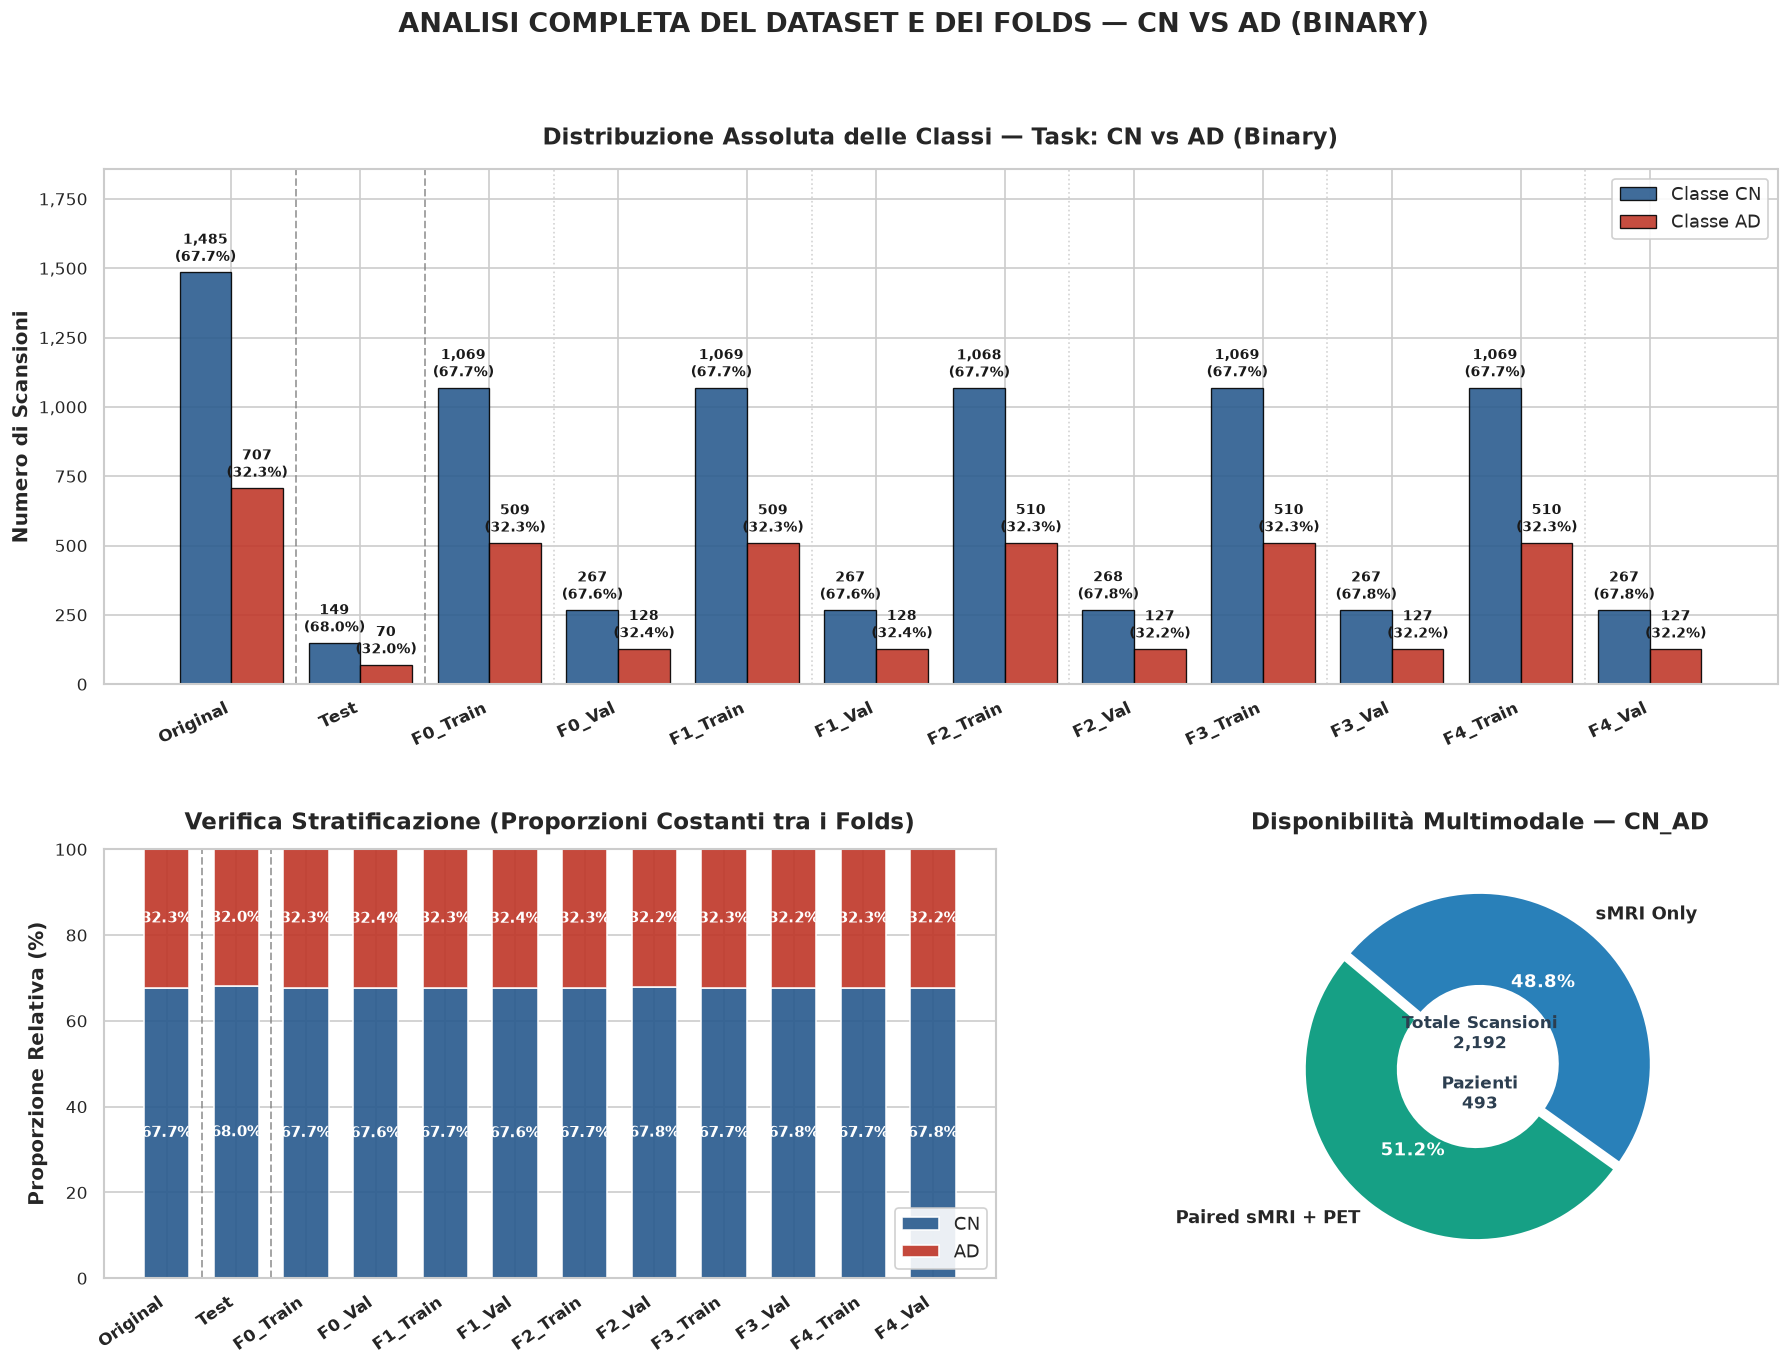


TABELLA STATISTICHE DETTAGLIATE PER TUTTI GLI SPLIT: CN_AD


,Split,Total Scans,Unique Patients,CN Count,AD Count,CN %,AD %,Age Mean±Std,MMSE Mean±Std,Paired Both %
0,Original,2192,493,1485,707,67.746350,32.253650,74.8 ± 6.5,27.1 ± 3.3,51.2%
1,Test,219,49,149,70,68.036530,31.963470,73.3 ± 5.9,26.7 ± 3.3,41.6%
2,F0_Train,1578,355,1069,509,67.743980,32.256020,75.1 ± 6.5,27.1 ± 3.3,52.5%
3,F0_Val,395,89,267,128,67.594937,32.405063,74.6 ± 7.0,27.4 ± 3.1,51.4%
4,F1_Train,1578,355,1069,509,67.743980,32.256020,75.0 ± 6.7,27.2 ± 3.3,52.5%
5,F1_Val,395,89,267,128,67.594937,32.405063,74.7 ± 6.3,27.0 ± 3.2,51.6%
6,F2_Train,1578,355,1068,510,67.680608,32.319392,74.9 ± 6.5,27.3 ± 3.2,52.1%
7,F2_Val,395,89,268,127,67.848101,32.151899,75.3 ± 6.8,26.9 ± 3.6,53.2%
8,F3_Train,1579,356,1069,510,67.701077,32.298923,75.0 ± 6.6,27.1 ± 3.2,52.4%
9,F3_Val,394,88,267,127,67.766497,32.233503,74.9 ± 6.3,27.4 ± 3.3,52.0%


In [4]:
task_cn_ad = 'cn_ad'
datasets_cn_ad = load_task_datasets(task_cn_ad)
stats_cn_ad = extract_split_statistics(datasets_cn_ad)

plot_task_analysis(task_cn_ad, datasets_cn_ad, stats_cn_ad)


## 2. TASK: `cn_mci` (Cognitively Normal vs Mild Cognitive Impairment)
Classificazione binaria per la diagnosi precoce tra soggetti normali (CN) e deficit cognitivo lieve (MCI).


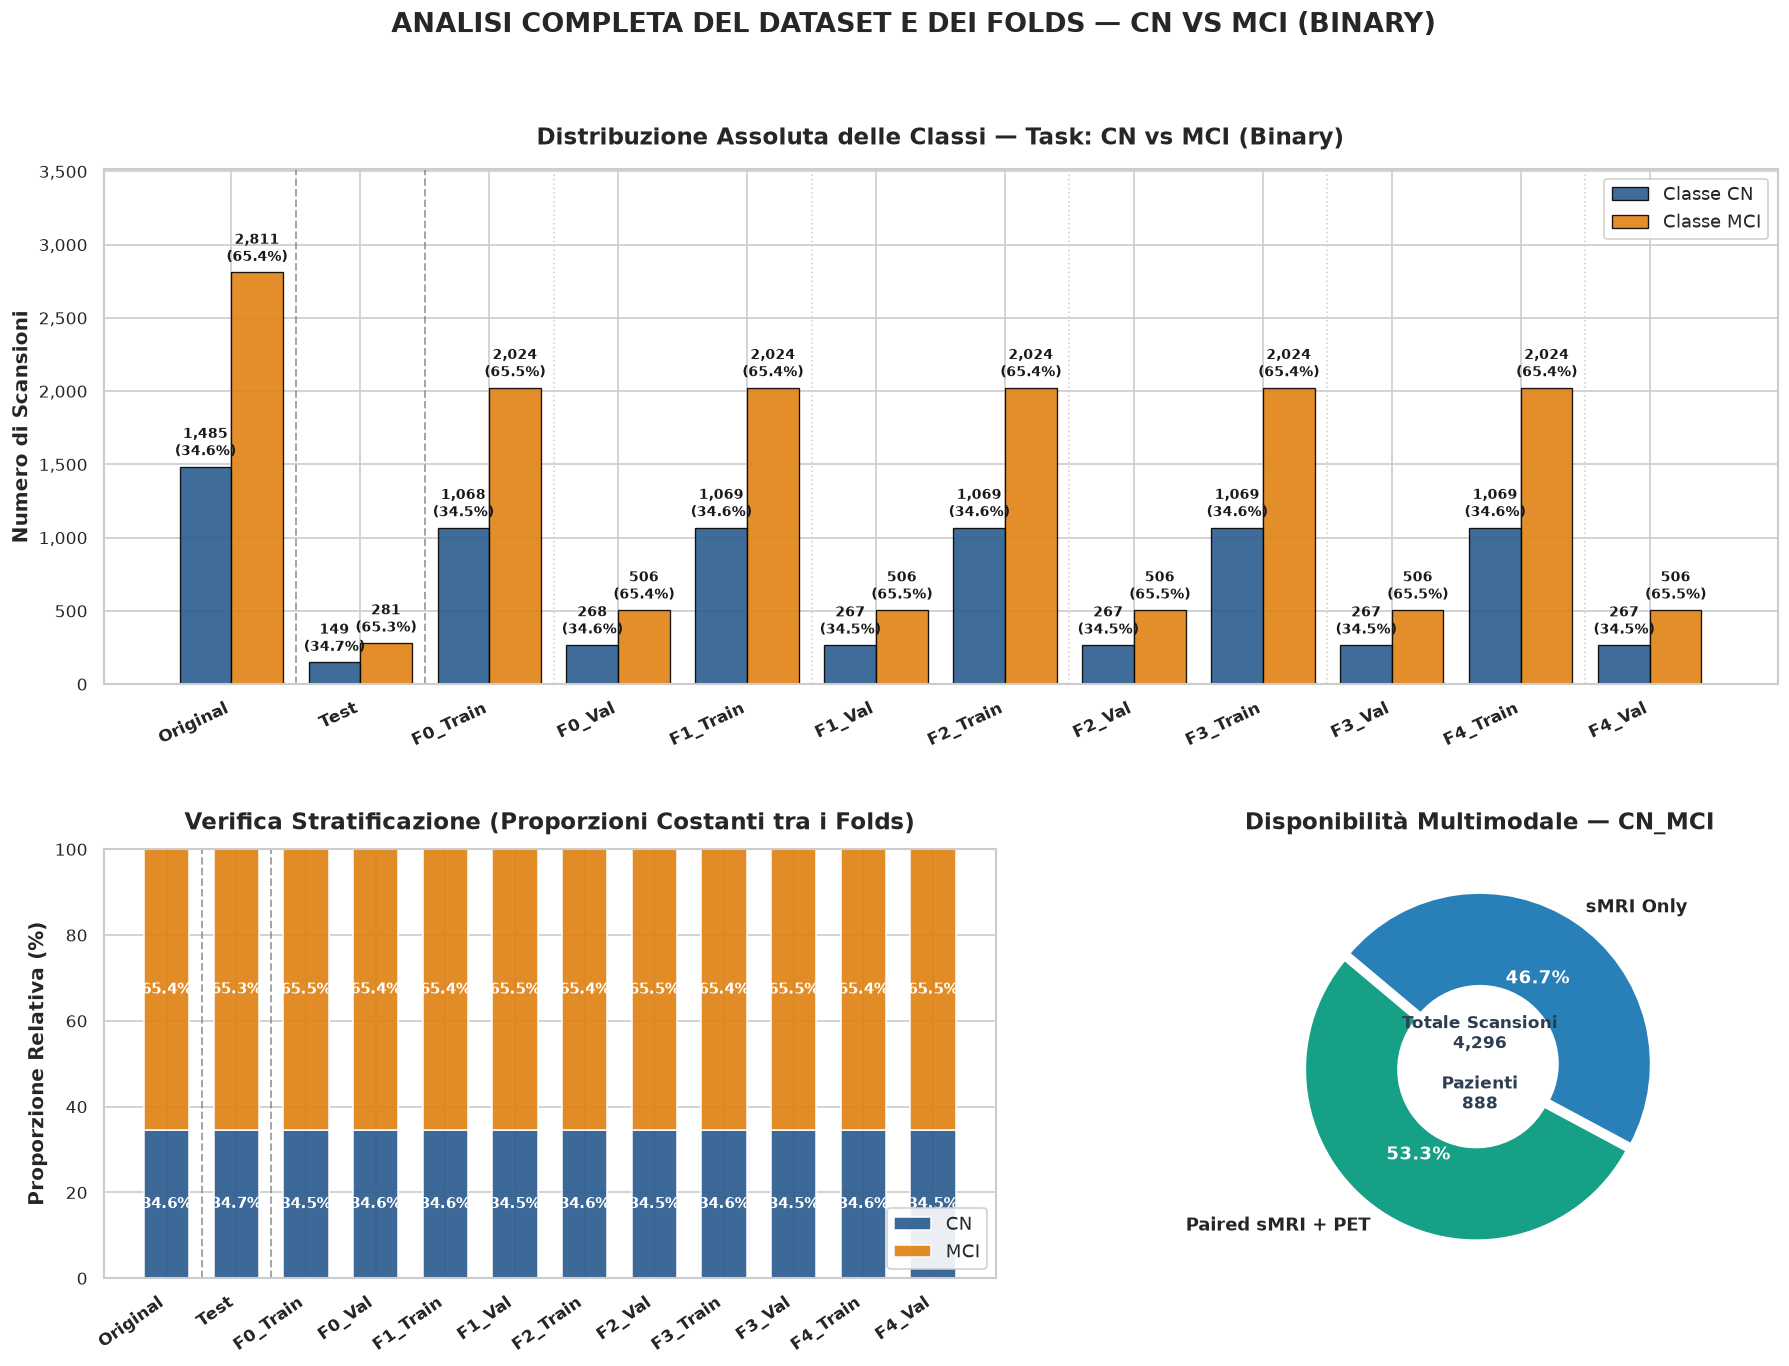


TABELLA STATISTICHE DETTAGLIATE PER TUTTI GLI SPLIT: CN_MCI


,Split,Total Scans,Unique Patients,CN Count,MCI Count,CN %,MCI %,Age Mean±Std,MMSE Mean±Std,Paired Both %
0,Original,4296,888,1485,2811,34.567039,65.432961,73.2 ± 7.1,28.1 ± 1.8,53.3%
1,Test,430,88,149,281,34.651163,65.348837,72.9 ± 7.6,28.0 ± 1.7,51.4%
2,F0_Train,3092,639,1068,2024,34.540750,65.459250,73.2 ± 7.2,28.1 ± 1.8,53.9%
3,F0_Val,774,161,268,506,34.625323,65.374677,73.3 ± 6.4,28.3 ± 1.8,51.7%
4,F1_Train,3093,640,1069,2024,34.561914,65.438086,73.1 ± 7.1,28.2 ± 1.7,54.2%
5,F1_Val,773,160,267,506,34.540750,65.459250,73.8 ± 7.0,28.1 ± 1.9,50.7%
6,F2_Train,3093,641,1069,2024,34.561914,65.438086,73.3 ± 7.2,28.2 ± 1.8,53.1%
7,F2_Val,773,159,267,506,34.540750,65.459250,72.8 ± 6.7,28.1 ± 1.7,55.2%
8,F3_Train,3093,640,1069,2024,34.561914,65.438086,73.4 ± 6.9,28.1 ± 1.8,53.2%
9,F3_Val,773,160,267,506,34.540750,65.459250,72.4 ± 7.6,28.3 ± 1.6,54.9%


In [ ]:
task_cn_mci = 'cn_mci'
datasets_cn_mci = load_task_datasets(task_cn_mci)
stats_cn_mci = extract_split_statistics(datasets_cn_mci)

plot_task_analysis(task_cn_mci, datasets_cn_mci, stats_cn_mci)


## 3. TASK: `mci_ad` (Mild Cognitive Impairment vs Alzheimer's Disease)
Classificazione prognostica fondamentale: discriminazione tra MCI e transizione/stato di Alzheimer conclamato (AD).


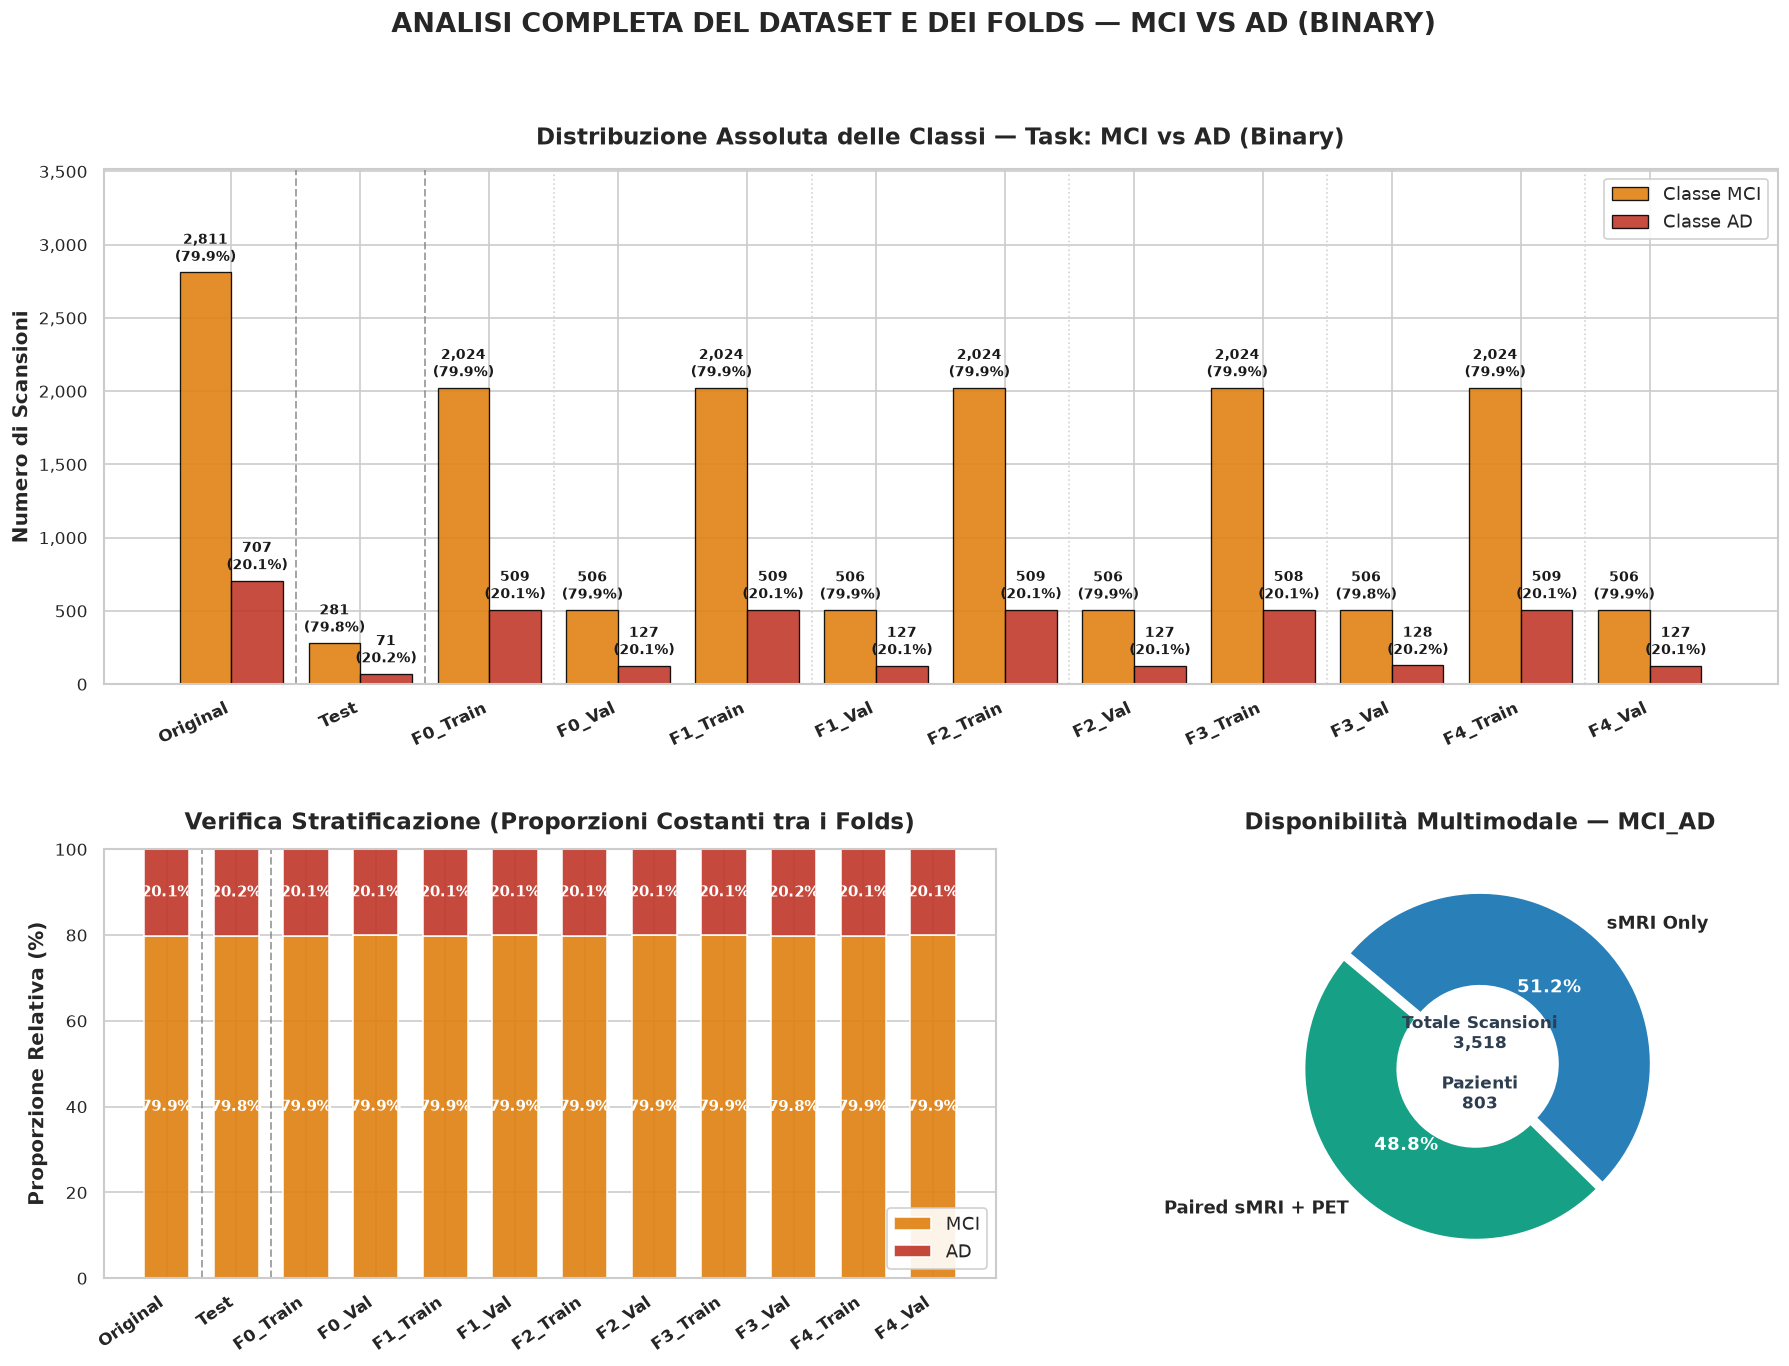


TABELLA STATISTICHE DETTAGLIATE PER TUTTI GLI SPLIT: MCI_AD


,Split,Total Scans,Unique Patients,MCI Count,AD Count,MCI %,AD %,Age Mean±Std,MMSE Mean±Std,Paired Both %
0,Original,3518,803,2811,707,79.903354,20.096646,73.0 ± 7.7,26.7 ± 2.7,48.8%
1,Test,352,80,281,71,79.829545,20.170455,73.6 ± 7.1,26.9 ± 2.7,55.7%
2,F0_Train,2533,579,2024,509,79.905251,20.094749,72.8 ± 7.6,26.6 ± 2.7,48.7%
3,F0_Val,633,144,506,127,79.936809,20.063191,73.7 ± 8.1,26.7 ± 2.6,45.2%
4,F1_Train,2533,578,2024,509,79.905251,20.094749,73.0 ± 7.8,26.7 ± 2.7,48.6%
5,F1_Val,633,145,506,127,79.936809,20.063191,73.0 ± 7.6,26.5 ± 2.5,45.5%
6,F2_Train,2533,579,2024,509,79.905251,20.094749,73.2 ± 7.8,26.7 ± 2.6,46.7%
7,F2_Val,633,144,506,127,79.936809,20.063191,72.2 ± 7.7,26.5 ± 2.8,53.4%
8,F3_Train,2532,578,2024,508,79.936809,20.063191,73.1 ± 7.7,26.6 ± 2.7,49.3%
9,F3_Val,634,145,506,128,79.810726,20.189274,72.6 ± 7.8,26.9 ± 2.6,42.9%


In [ ]:
task_mci_ad = 'mci_ad'
datasets_mci_ad = load_task_datasets(task_mci_ad)
stats_mci_ad = extract_split_statistics(datasets_mci_ad)

plot_task_analysis(task_mci_ad, datasets_mci_ad, stats_mci_ad)


## 4. TASK: `cn_mci_ad` (CN vs MCI vs AD — Multiclass)
Classificazione a 3 classi sull'intero spettro patologico: CN, MCI e AD contemporaneamente.


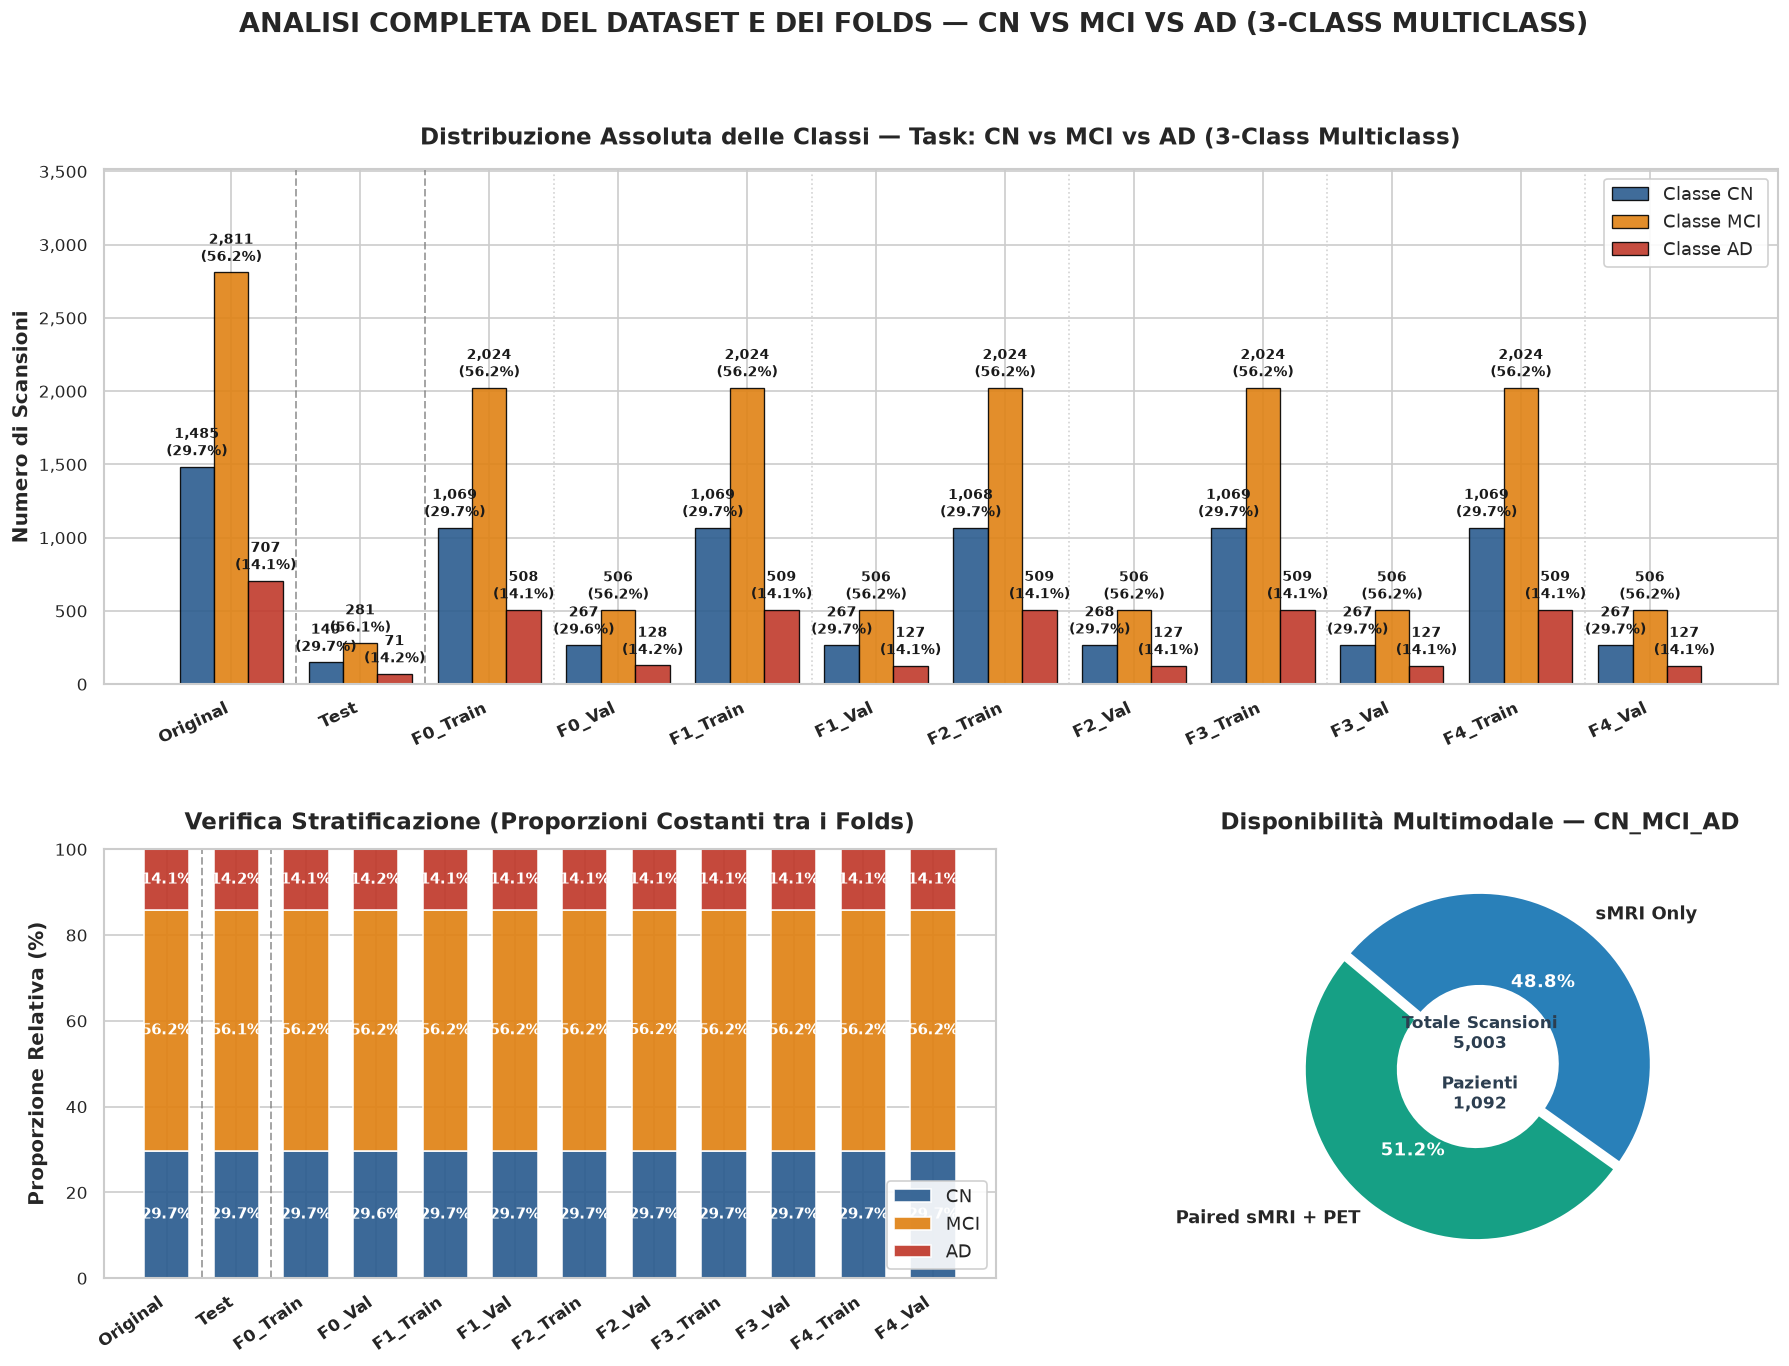


TABELLA STATISTICHE DETTAGLIATE PER TUTTI GLI SPLIT: CN_MCI_AD


,Split,Total Scans,Unique Patients,CN Count,MCI Count,AD Count,CN %,MCI %,AD %,Age Mean±Std,MMSE Mean±Std,Paired Both %
0,Original,5003,1092,1485,2811,707,29.682191,56.186288,14.131521,73.5 ± 7.2,27.4 ± 2.6,51.2%
1,Test,501,110,149,281,71,29.740519,56.087824,14.171657,73.4 ± 6.8,27.4 ± 2.7,55.7%
2,F0_Train,3601,786,1069,2024,508,29.686198,56.206609,14.107192,73.4 ± 7.3,27.5 ± 2.5,51.0%
3,F0_Val,901,196,267,506,128,29.633740,56.159822,14.206437,74.0 ± 7.2,27.2 ± 2.7,49.9%
4,F1_Train,3602,786,1069,2024,509,29.677957,56.191005,14.131038,73.7 ± 7.2,27.4 ± 2.6,49.1%
5,F1_Val,900,196,267,506,127,29.666667,56.222222,14.111111,72.6 ± 7.4,27.4 ± 2.6,57.6%
6,F2_Train,3601,785,1068,2024,509,29.658428,56.206609,14.134963,73.5 ± 7.3,27.4 ± 2.6,50.5%
7,F2_Val,901,197,268,506,127,29.744728,56.159822,14.095450,73.6 ± 7.3,27.4 ± 2.6,51.8%
8,F3_Train,3602,786,1069,2024,509,29.677957,56.191005,14.131038,73.4 ± 7.2,27.4 ± 2.6,50.8%
9,F3_Val,900,196,267,506,127,29.666667,56.222222,14.111111,73.7 ± 7.5,27.6 ± 2.4,50.7%


In [ ]:
task_cn_mci_ad = 'cn_mci_ad'
datasets_cn_mci_ad = load_task_datasets(task_cn_mci_ad)
stats_cn_mci_ad = extract_split_statistics(datasets_cn_mci_ad)

plot_task_analysis(task_cn_mci_ad, datasets_cn_mci_ad, stats_cn_mci_ad)


## 5. Confronto Globale Cross-Task & Sintesi Clinico-Demografica
Questo cruscotto riassuntivo mette a confronto diretto la distribuzione delle classi e il bilanciamento su tutti i 4 task contemporaneamente.


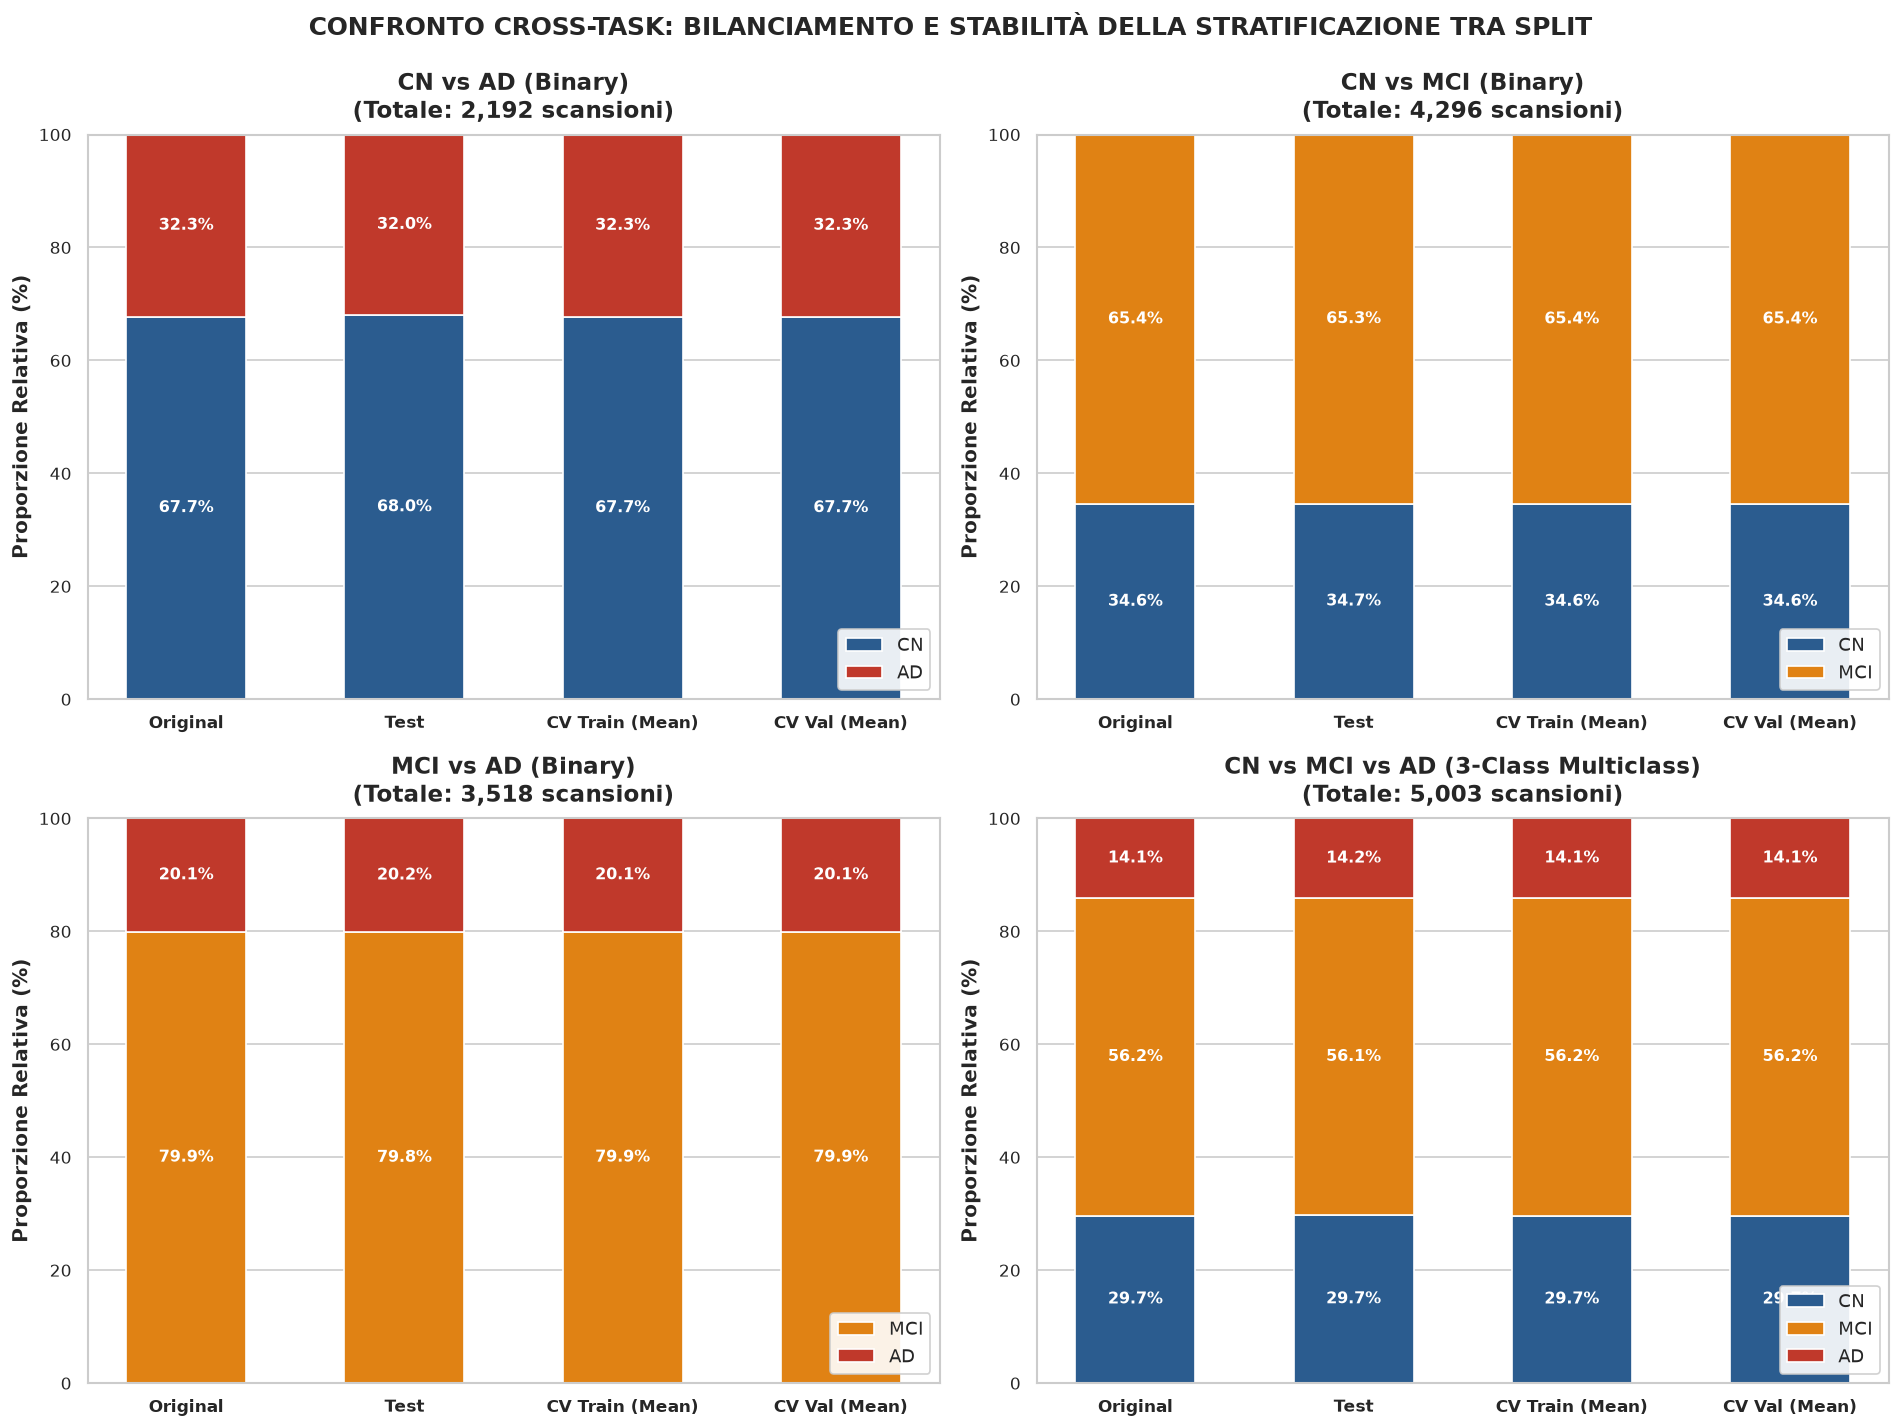

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(16, 12))
axes = axes.flatten()

all_task_stats = {}

for idx, task in enumerate(TASKS):
    ax = axes[idx]
    ds = load_task_datasets(task)
    st = extract_split_statistics(ds)
    all_task_stats[task] = st
    
    folds_train = st[st['Split'].str.endswith('Train')]
    folds_val = st[st['Split'].str.endswith('Val')]
    
    classes = [c for c in ['CN', 'MCI', 'AD'] if st[f'{c} Count'].sum() > 0]
    
    summary_splits = ['Original', 'Test', 'CV Train (Mean)', 'CV Val (Mean)']
    
    summary_data = []
    # 1. Original
    orig_row = st[st['Split'] == 'Original'].iloc[0]
    summary_data.append([orig_row[f'{c} %'] for c in classes])
    
    # 2. Test
    test_row = st[st['Split'] == 'Test'].iloc[0]
    summary_data.append([test_row[f'{c} %'] for c in classes])
    
    # 3. CV Train Mean
    summary_data.append([folds_train[f'{c} %'].mean() for c in classes])
    
    # 4. CV Val Mean
    summary_data.append([folds_val[f'{c} %'].mean() for c in classes])
    
    summary_arr = np.array(summary_data)  # shape (4, len(classes))
    
    x = np.arange(len(summary_splits))
    bottom = np.zeros(len(summary_splits))
    
    for c_idx, cls in enumerate(classes):
        vals = summary_arr[:, c_idx]
        bars = ax.bar(x, vals, bottom=bottom, label=cls, color=CLASS_COLORS[cls],
                      edgecolor='white', linewidth=1.0, width=0.55)
        for b_idx, (b, val) in enumerate(zip(bars, vals)):
            if val > 6:
                ax.text(b.get_x() + b.get_width() / 2, bottom[b_idx] + val / 2,
                        f'{val:.1f}%', ha='center', va='center', color='white', weight='bold', fontsize=9.5)
        bottom += vals
        
    ax.set_xticks(x)
    ax.set_xticklabels(summary_splits, weight='bold', fontsize=10)
    ax.set_ylim(0, 100)
    ax.set_ylabel('Proporzione Relativa (%)', weight='bold')
    ax.set_title(f'{TASK_LABELS[task]}\n(Totale: {int(orig_row["Total Scans"]):,} scansioni)', pad=10)
    ax.legend(loc='lower right', frameon=True, facecolor='white', framealpha=0.9)

plt.suptitle('CONFRONTO CROSS-TASK: BILANCIAMENTO E STABILITÀ DELLA STRATIFICAZIONE TRA SPLIT',
             fontsize=15, weight='bold', y=0.99)
plt.tight_layout()
plt.show()


In [ ]:
# Tabella Riepilogativa Clinico-Demografica per Task e Classe
summary_records = []

for task in TASKS:
    pop_df = pd.read_csv(f'data/processed/population_topology/{task}/population_dataset.csv')
    
    for cls in sorted(pop_df['original_class'].unique()):
        sub_df = pop_df[pop_df['original_class'] == cls]
        
        m_count = (sub_df['PTGENDER'] == 'Male').sum() if 'PTGENDER' in sub_df else 0
        f_count = (sub_df['PTGENDER'] == 'Female').sum() if 'PTGENDER' in sub_df else 0
        apoe_pos = (sub_df['APOE4'] > 0).sum() if 'APOE4' in sub_df else 0
        
        summary_records.append({
            'Task': task,
            'Class': cls,
            'Scans': len(sub_df),
            'Unique Patients': sub_df['PTID'].nunique(),
            'Age (Mean ± SD)': f"{sub_df['AGE'].mean():.1f} ± {sub_df['AGE'].std():.1f}",
            'Gender (M / F)': f"{m_count} / {f_count} ({(m_count/len(sub_df)*100):.1f}% M)",
            'MMSE (Mean ± SD)': f"{sub_df['MMSE'].mean():.1f} ± {sub_df['MMSE'].std():.1f}",
            'Education Years': f"{sub_df['PTEDUCAT'].mean():.1f} ± {sub_df['PTEDUCAT'].std():.1f}",
            'APOE4 Carrier %': f"{(apoe_pos / len(sub_df) * 100):.1f}%",
            'PET Coverage %': f"{(sub_df['has_pet'].sum() / len(sub_df) * 100):.1f}%"
        })

summary_table = pd.DataFrame(summary_records)
print("=== TABELLA DEMOGRAFICA E CLINICA GLOBALE ===")
display(summary_table)


=== TABELLA DEMOGRAFICA E CLINICA GLOBALE ===


,Task,Class,Scans,Unique Patients,Age (Mean ± SD),Gender (M / F),MMSE (Mean ± SD),Education Years,APOE4 Carrier %,PET Coverage %
0,cn_ad,AD,707,204,75.4 ± 7.6,377 / 330 (53.3% M),22.9 ± 2.1,15.3 ± 2.8,70.3%,38.9%
1,cn_ad,CN,1485,289,74.5 ± 5.9,719 / 766 (48.4% M),29.1 ± 1.1,16.4 ± 2.6,26.7%,57.1%
2,cn_mci,CN,1485,289,74.5 ± 5.9,719 / 766 (48.4% M),29.1 ± 1.1,16.4 ± 2.6,26.7%,57.1%
3,cn_mci,MCI,2811,599,72.4 ± 7.6,1583 / 1228 (56.3% M),27.6 ± 1.8,16.0 ± 2.9,47.0%,51.3%
4,mci_ad,AD,707,204,75.4 ± 7.6,377 / 330 (53.3% M),22.9 ± 2.1,15.3 ± 2.8,70.3%,38.9%
5,mci_ad,MCI,2811,599,72.4 ± 7.6,1583 / 1228 (56.3% M),27.6 ± 1.8,16.0 ± 2.9,47.0%,51.3%
6,cn_mci_ad,AD,707,204,75.4 ± 7.6,377 / 330 (53.3% M),22.9 ± 2.1,15.3 ± 2.8,70.3%,38.9%
7,cn_mci_ad,CN,1485,289,74.5 ± 5.9,719 / 766 (48.4% M),29.1 ± 1.1,16.4 ± 2.6,26.7%,57.1%
8,cn_mci_ad,MCI,2811,599,72.4 ± 7.6,1583 / 1228 (56.3% M),27.6 ± 1.8,16.0 ± 2.9,47.0%,51.3%


## Conclusioni e Osservazioni Metodologiche

1. **Stratificazione Perfetta**:
   - In ciascuno dei 4 task, la proporzione relativa di ciascuna classe diagnostica (`CN`, `MCI`, `AD`) rimane **rigorosamente costante** tra:
     - Dataset originale (`population_topology`)
     - Holdout test split (`splits/<task>/test.csv`)
     - I 5 fold di cross-validation sia in fase di Training che di Validation.
2. **Separazione Paziente (Zero Data-Leakage)**:
   - I fold sono partizionati a livello di paziente (`PTID`), garantendo che scansioni longitudinali dello stesso soggetto non appaiano contemporaneamente in training e validation/test.
3. **Copertura Multimodale**:
   - Il 100% dei soggetti dispone di risonanza magnetica sMRI (`has_mri = True`), e oltre il 50% dispone di scansione PET co-registrata (`has_pet = True`), consentendo l'integrazione di feature tensoriali multimodali e modelli GNN cross-modali.
